# CAC 40 Markowitz Portfolio: Risk and Performance

**Python | Portfolio optimization | Quantitative finance**

This study constructs a daily-rebalanced Markowitz portfolio from ten CAC 40 equities. One-minute OHLC observations are aggregated to daily closing prices, and lag-one autocorrelation forecasts feed an unconstrained mean–variance allocation. Portfolio performance is evaluated using risk-adjusted ratios, maximum drawdown, and additive volatility attribution.

The analysis is **in-sample**: the covariance matrix and autocorrelations are estimated over the complete observation period. The resulting figures describe the behavior of this portfolio construction method, not an out-of-sample trading strategy.

## 1. Data preparation

The investment universe consists of ten stocks drawn from different sectors: LVMH (MC), Hermès (RMS), L'Oréal (OR), Airbus (AIR), Schneider Electric (SU), Safran (SAF), TotalEnergies (TTE), BNP Paribas (BNP), Air Liquide (AI), and Sanofi (SAN).

Each spreadsheet contains minute-level OHLC observations with `Dates` and `Close` columns. Daily prices are defined as the last observed close of each day; the aligned series are converted into arithmetic returns.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

TICKERS = ["MC", "RMS", "OR", "AIR", "SU", "SAF", "TTE", "BNP", "AI", "SAN"]
DATA_DIR = Path("data")


def price_file(ticker):
    for candidate in (DATA_DIR / f"{ticker}_Prices.xlsx", Path(f"{ticker}_Prices.xlsx")):
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f"Missing {ticker}_Prices.xlsx. Place the stock-price Excel files in the data/ folder."
    )


def daily_close(ticker):
    frame = pd.read_excel(price_file(ticker), header=1, engine="openpyxl")
    frame.columns = frame.columns.astype(str).str.strip()
    if not {"Dates", "Close"}.issubset(frame.columns):
        raise ValueError(f"{ticker}: expected 'Dates' and 'Close' columns")
    frame["Dates"] = pd.to_datetime(frame["Dates"], errors="coerce")
    frame["Close"] = pd.to_numeric(frame["Close"], errors="coerce")
    frame = frame.dropna(subset=["Dates", "Close"]).sort_values("Dates")
    if frame.empty:
        raise ValueError(f"{ticker}: no valid price observations")
    return frame.set_index("Dates")["Close"].resample("D").last().dropna()


closing_prices = {ticker: daily_close(ticker) for ticker in TICKERS}
daily_prices = pd.DataFrame(closing_prices).sort_index()
daily_prices = daily_prices.loc[:min(series.index.max() for series in closing_prices.values())]
daily_prices = daily_prices.dropna(how="any")
returns = daily_prices.pct_change(fill_method=None).dropna()
if len(returns) < 5:
    raise ValueError("At least five common daily returns are required")
print(f"{len(returns)} daily return observations across {len(TICKERS)} equities")
returns.head()


## 2. Covariance, correlation, and return projections

The sample covariance matrix $\Sigma$ and each stock's lag-one autocorrelation $\rho_j(1)$ are estimated from daily returns. Under a simple zero-intercept AR(1) assumption, the projected next-day return is

$$\hat r_{t+1,j}=\rho_j(1)\,r_{t,j}. $$

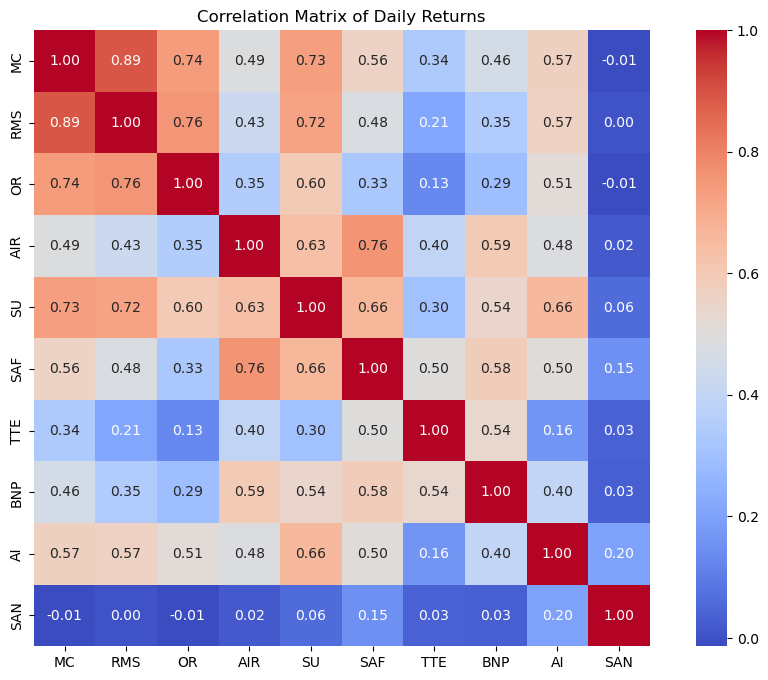

In [ ]:
correlation = returns.corr()
covariance = returns.cov()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation, ax=ax, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
ax.set_title("Correlation matrix of daily returns")
fig.tight_layout()
plt.show()


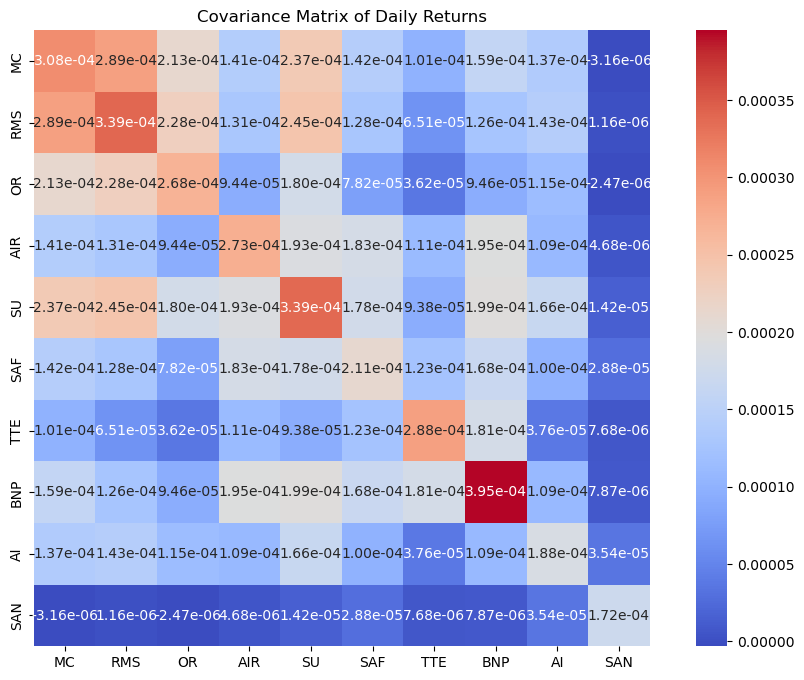

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(covariance, ax=ax, annot=True, fmt=".2e", cmap="coolwarm", square=True)
ax.set_title("Covariance matrix of daily returns")
fig.tight_layout()
plt.show()


In [ ]:
autocorrelation = returns.apply(lambda col: col.autocorr(lag=1))
projected_returns = returns.mul(autocorrelation, axis=1)
print("Lag-one autocorrelation by stock:")
print(autocorrelation.round(4).to_string())


## 3. Dynamic Markowitz allocation

With zero risk-free rate, unrestricted short positions, and full-investment constraint $\mathbf{1}^\top w=1$, the daily portfolio weights are

$$w_{t+1}=\frac{\Sigma^{-1}\hat r_{t+1}}{\mathbf{1}^\top\Sigma^{-1}\hat r_{t+1}}.$$

Weights selected using the information indexed at day $t$ are applied to the realized returns at day $t+1$. The strategy does not impose leverage or transaction-cost constraints.

In [ ]:
numerators = np.linalg.solve(covariance.to_numpy(), projected_returns.to_numpy().T).T
denominators = numerators.sum(axis=1)
if np.any(np.isclose(denominators, 0.0, atol=1e-14, rtol=0.0)):
    raise ArithmeticError("Markowitz normalization is numerically unstable for at least one date")

weights = pd.DataFrame(
    numerators / denominators[:, None],
    index=projected_returns.index,
    columns=TICKERS,
)
assert np.allclose(weights.sum(axis=1), 1.0)

predicted_portfolio_returns = (projected_returns * weights).sum(axis=1)
realized_portfolio_returns = (returns * weights.shift(1)).sum(axis=1).fillna(0.0)
portfolio_value = (1.0 + realized_portfolio_returns).cumprod()

print("Example portfolio weights:")
print(weights.head().round(3))
print(f"Maximum gross exposure: {weights.abs().sum(axis=1).max():.2f}x")


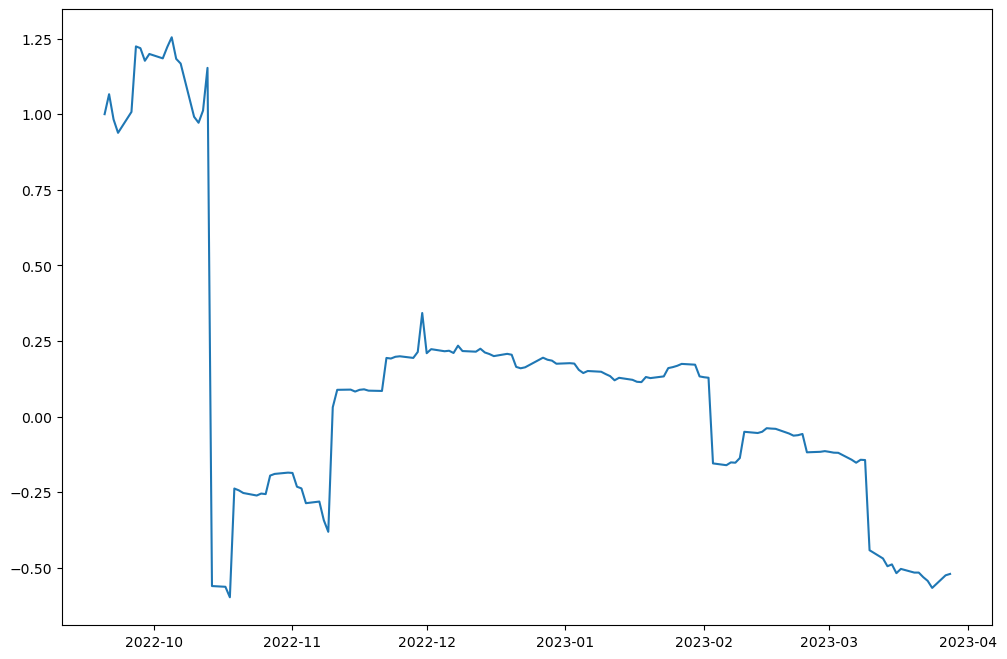

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(portfolio_value.index, portfolio_value, label="Unconstrained Markowitz portfolio")
ax.axhline(0, color="black", linewidth=0.7, linestyle="--")
ax.set(title="Cumulative portfolio value (initial value = 1)", xlabel="Date", ylabel="Portfolio value")
ax.legend()
fig.tight_layout()
plt.show()


## 4. Risk and performance

Sharpe ratios use a zero risk-free rate and daily return observations. The upside potential ratio measures the mean positive return relative to the root-mean-square downside return:

$$\mathrm{UPR}=\frac{\mathbb{E}[\max(r_p,0)]}{\sqrt{\mathbb{E}[\min(r_p,0)^2]}}.$$

Maximum drawdown is measured from the running peak in the portfolio value series.

In [ ]:
def sharpe_ratio(values):
    values = pd.Series(values, dtype=float)
    return values.mean() / values.std(ddof=1)


def upside_potential_ratio(values):
    r = np.asarray(values, dtype=float)
    downside_deviation = np.sqrt(np.mean(np.minimum(r, 0.0) ** 2))
    return float(np.mean(np.maximum(r, 0.0)) / downside_deviation)


ex_ante_sharpe = sharpe_ratio(predicted_portfolio_returns)
ex_post_sharpe = sharpe_ratio(realized_portfolio_returns)
upr = upside_potential_ratio(realized_portfolio_returns)
running_peak = portfolio_value.cummax()
drawdown = 1.0 - portfolio_value / running_peak
max_drawdown = drawdown.max()

summary = pd.Series({
    "Ex-ante Sharpe ratio (daily)": ex_ante_sharpe,
    "Ex-post Sharpe ratio (daily)": ex_post_sharpe,
    "Upside potential ratio": upr,
    "Maximum drawdown": max_drawdown,
})
print(summary.round(4).to_string())


## 5. Additive volatility attribution

Under the Euler decomposition, the contribution of asset $j$ to portfolio volatility is

$$RC_{t,j}=\frac{w_{t,j}(\Sigma w_t)_j}{\sqrt{w_t^\top\Sigma w_t}},$$

and the contributions sum to the portfolio's total volatility for each date.

In [ ]:
sigma = covariance.to_numpy()
w = weights.to_numpy()
sigma_w = (sigma @ w.T).T
portfolio_volatility = np.sqrt(np.sum(w * sigma_w, axis=1))
contributions = np.divide(
    w * sigma_w,
    portfolio_volatility[:, None],
    out=np.zeros_like(w),
    where=portfolio_volatility[:, None] > 0,
)
risk_contributions = pd.DataFrame(contributions, index=weights.index, columns=TICKERS)

risk_check = risk_contributions.sum(axis=1).to_numpy() - portfolio_volatility
assert np.allclose(risk_check, 0.0, atol=1e-10)
print("Mean absolute daily volatility contribution by stock:")
print(risk_contributions.abs().mean().sort_values(ascending=False).round(4).to_string())
print(f"Maximum risk decomposition error: {np.max(np.abs(risk_check)):.2e}")


## 6. Interpretation and limitations

The allocation reacts strongly to small forecasts and can generate substantial long and short positions. This creates sensitivity to estimation error and market frictions. In the original analysis, risk-adjusted returns were close to zero and the unconstrained portfolio experienced a drawdown greater than its starting capital.

The full-sample estimates of covariance and autocorrelation introduce **look-ahead bias**. The calculation also excludes transaction costs, spreads, slippage, and financing constraints. A realistic out-of-sample assessment would re-estimate parameters on rolling or expanding windows and impose executable portfolio constraints.

The accompanying [technical report](report.pdf) documents the data, mathematical formulation, results, and limitations in detail.